<h2>
  Vignette 02: Virtual views for ROI selection and analysis (the `ViewPort`)<br>
  <span style="font-size: 12px; font-weight: normal; display: block">
    <i>"With your feet in the air and head on the ground, try this trick and spin it around" -- Pixies</i><br>
  </span>
</h2>

One of the most important features of platpy is the `ViewPort`.  `ViewPort`s allow for rendering any data layer how you want to work with it -- cropped, scaled, rotated, flipped as needed.  This is obviously useful for displaying your data.  But `ViewPort`s can also be used for data analysis: you can mark out ROIs on a ViewPort image, and the ViewPort contains metadata that allows you to map those results back home to Micron Space.  The real data stays safely in its native state, so you're not blurring images by repeatedly re-rendering them, or altering your 'Omic data before analysis.

In [13]:
%load_ext autoreload
%autoreload 2

# platpy imports
from platpy.io_utils import load_sample 
from pathlib import Path

# UPDATE THIS TO YOUR LOCAL FOLDER PATH (pointing to the directory)
save_path = Path.home() / 'platpy_data' / 'VisiumSample'

# Load the sample! (Notice how fast this is, even with massive images)
# With verbose=True, platpy will automatically print the inventory of what was loaded.
sample = load_sample(save_path, verbose=True)

# Note: load_sample() already drops the 2um bin by default (load_2um_bin=False)
# -- it is noisy on its own and not persisted unless explicitly requested.


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
  - Images available: 'dapi' (16g), 'neun' (16g), 'detected' (24c), 'hires' (24c), 'lowres' (24c)
  - Image channels loaded: dapi, neun, detected, hires, lowres
  - Omic channels loaded: spots
  - Cell channels loaded: 
  - ROIs loaded: 


#### Introducing the ViewPort — a clean and unified way to look at your data

The ViewPort is platpy's compositing engine. You tell it **where** to look (a center point and field-of-view in microns), and optionally how to orient the view (flip, rotation). The render width in pixels comes from `sample.screen_width` (default 1024) so you set it once, not every time.

The key design principle: **add data first, configure display second.** `add_layer()` just registers a channel. `adjust_layer()` sets how it looks — tint, contrast, blend mode, gene expression mapping — all lazily applied at `render()` time. The original channel data is never modified.

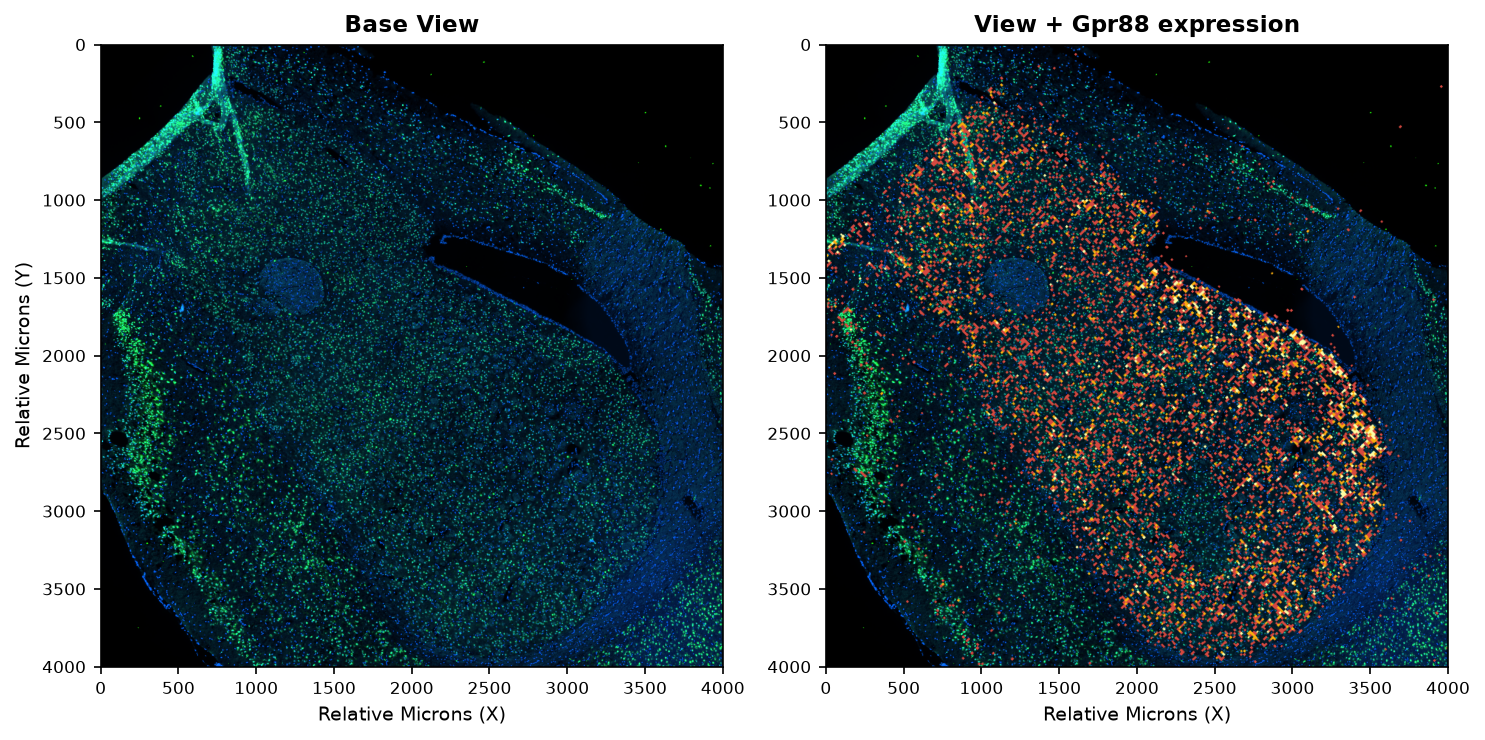

In [14]:
from platpy.plot_utils import plot_image_grid
import matplotlib.pyplot as plt

# 1. Create the ViewPort — camera position, field of view, and orientation.
#    sample.viewport() uses sample.screen_width (default 1024 px) automatically.
new_overlay = sample.viewport(
    center_um=(2500, 2500),
    fov_um=(4000, 4000),
    flip_x=False,
    rotation_deg=45,
    background_color='black'
)

# 2. Add layers and configure their display — all processing happens at render time.
#    The raw channel data is never modified.
new_overlay.add_layer(sample.images['dapi']).adjust_layer(
    tint='xkcd:bright blue', gamma=1.2, percentile_clip=(5, 99), blend_mode='lighten'
)
new_overlay.add_layer(sample.images['neun']).adjust_layer(
    tint='xkcd:electric green', gamma=0.8, percentile_clip=(5, 99), blend_mode='lighten'
)
# 4. Now we render the image, specifying the view and two layers.
first_view_image = new_overlay.render()

# 5. Let's add a layer showing the expression of a striatum specific gene on top.
#    Note -- the 'omic layer has its own settings for gamma and clipping; these apply
#    to the genomic data itself.  The adjust_layer settings apply to the rendered
#    pixel values, just like before, to control brightness and contrast.

new_overlay.add_layer(sample.omics['spots'], name='spots', overwrite=True)\
        .adjust_omic(gene_name='Gpr88',   # Omic settings
                cmap_name='inferno',
                blend_mode='normal',
                gamma=1.0,                # this is for expression values
                omic_percentile_clip=(0, 99),
                # omic_alpha defaults to 1.0 if omitted
                alpha_gamma=1.5,          # alpha settings control fade in of overlay
                alpha_pass=0.5) \
        .adjust_layer(percentile_clip =(10, 95),  # this is for the rendered image layer
                      gamma=0.5)  # this is for the rendered pixel values, which may differ from the omic values due to gamma and clipping

# 6. Render the image again, now with the omic layer on top.
first_view_plus_expression = new_overlay.render()  

# 7. Display the two views side by side
plot_image_grid([first_view_image, first_view_plus_expression], titles=['Base View', 'View + Gpr88 expression'], width=10);


#### Changing the View
Now that we have the ViewPort stacked up, we can simply use the '.update_view' function to zoom in to look at a different region.

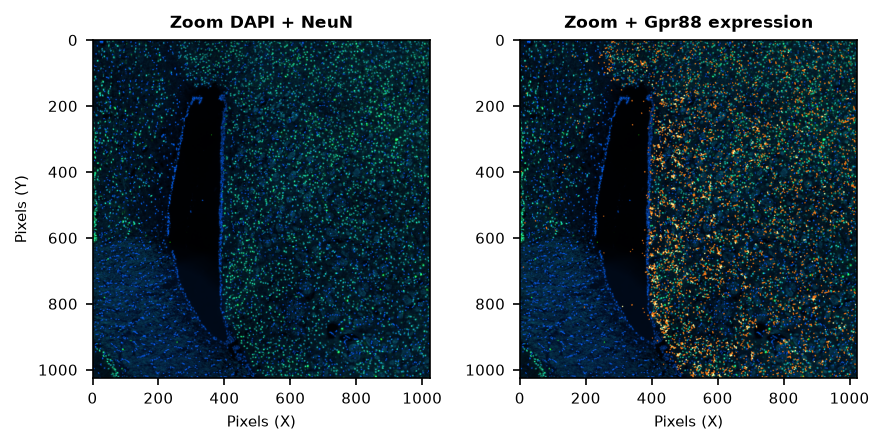

In [15]:

# 1. Move the camera — layers and display settings are preserved
new_overlay.update_view(center_um=(3000, 2850), fov_um=(2000, 2000), rotation_deg=-17, flip_x=True)

# 2. Let's render an image of the new view without the 'omic layer
new_overlay.adjust_layer('spots', visible=False)
second_view = new_overlay.render()

# 3. Now let's turn the omic layer back on and render again
new_overlay.adjust_layer('spots', visible=True)
second_view_plus_expression = new_overlay.render()  

# 7. Display all three views (we'll pass pre-rendered images so we can see their pixel sizes
plot_image_grid(second_view.image, second_view_plus_expression.image,
                titles=["Zoom DAPI + NeuN", "Zoom + Gpr88 expression"],
                columns=2, width=6, font_size='small');


#### The ViewPort provides a round-trip from Micron-space to your screen, and back. 

So the ViewPort not only displays images, but it keeps track of the underlying spatial transformations, and provides easy methods to convert between screen pixels and absolute spatial microns. (In this way the ViewPort is the "translator" for using GUI utilities like Napari for mapping out spatial ROIs on the screen and using them seamlessly to analye the underlying 'omic and image data)

Here we are going to map an ROI in "pixel space" from the current view, and map it back to microns

We're going to place an ROI on the view we just rendered in the last cell (marking some morphologically distinct features), then change the view.  The ROI we make is anchored to micron space, so it will stay correct no matter what we do to the view

Layer stack (bottom → top), 3 layer(s):
  [0] 'dapi'  (ImageChannel)  blend=lighten  visible
  [1] 'neun'  (ImageChannel)  blend=lighten  visible
  [2] 'spots'  (OmicChannel)  blend=normal  not_visible


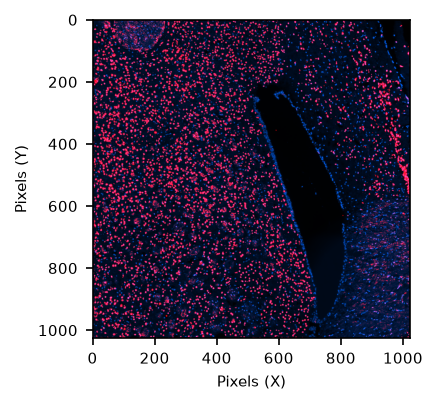

In [16]:
# Let's view the same sample again, but this time let's look at a pixel view.  We'll make a copy of
# the layer stack from last time, and set a new view. 

test_roi_view = new_overlay.clone()\
                    .update_view(center_um=(3000, 2650), fov_um=(2000, 2000), rotation_deg=0, flip_x=False)

test_roi_view.adjust_layer('spots', visible=False)

test_roi_view.adjust_layer('neun', tint='xkcd:bright red', gamma=0.1, percentile_clip=(10, 85), blend_mode='lighten')  # adjust display settings on the cloned view

plot_image_grid(test_roi_view.render().image, titles=None, width=3, font_size='small');

test_roi_view.list_layers();  # check that the same layers are still there, just with a different view

Layer stack (bottom → top), 4 layer(s):
  [0] 'dapi'  (ImageChannel)  blend=lighten  visible
  [1] 'neun'  (ImageChannel)  blend=lighten  visible
  [2] 'spots'  (OmicChannel)  blend=normal  not_visible
  [3] 'test_roi'  (ROIChannel)  blend=normal  visible


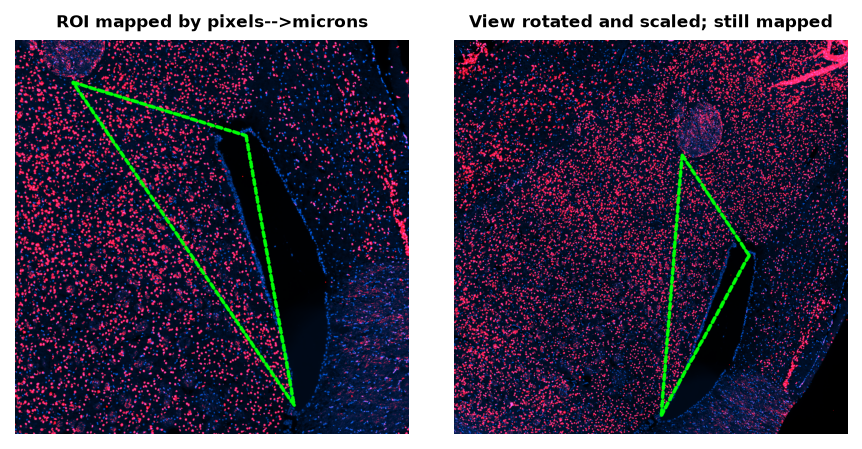

In [17]:
from platpy.channels import ROIChannel
import numpy as np

# 1. Define an ROI drawn on our current view (in pixel coordinates).
roi_to_map = np.array([[150, 110], [600, 250], [725, 950]])

# 2. Translate pixel coordinates to microns.
micron_roi_coordinates = test_roi_view.pixels_to_microns(roi_to_map)

# 3. Now we build an ROIChannel to hold those coordinates.  We'll use .set_style() to set their
#    display settings (line width, color, etc.); we can override these later if we change our mind
#    by using .adjust_layer() on the view layer.

test_roi = ROIChannel(name='test_roi',
                      polygons={'user_selection': micron_roi_coordinates}) \
                .set_style(line_color='xkcd:bright green', line_width=8, line_style='dashed')

test_roi_view.add_layer(test_roi, overwrite=True)   # display settings picked up automatically from set_style()

closeup_image = test_roi_view.render()

# Let's change the view, and re-render
test_roi_view.update_view(center_um=(2500, 2500), fov_um=(3000, 3000), rotation_deg=-39)

wider_image = test_roi_view.render()

plot_image_grid(closeup_image, wider_image, 
                titles=["ROI mapped by pixels-->microns","View rotated and scaled; still mapped"], 
                width=6, font_size='small', show_axis=False);

test_roi_view.list_layers();  # check that the same layers are still there, just with a different view


#### The ViewPort allows accurate transformations between microns and pixels

The screen images generated by the ViewPort aren't just for looks, we can use them to interact with our data in micron space. A pair of functions allow for mapping between points on a pixel render and micron space: `microns_to_pixels()` and `pixels_to_microns()`. In the next example, we show that our marked points stay resolved to a precise location, even when we change the view. Even after rotating, scaling, and flipping the image to make a screen preview, we're still able to track the locations back to micon-space with sub-micron accuracy! 

True Render Round-trip: Absolute Truth (RED) -> Detect -> Math -> Render (BLUE) -> Detect -> Error
  Spot 1: Start (2500.0, 2100.0) µm -> Return (2500.255, 2100.231) µm | error = 0.344 µm
  Spot 2: Start (3500.0, 3100.0) µm -> Return (3500.146, 3099.789) µm | error = 0.257 µm


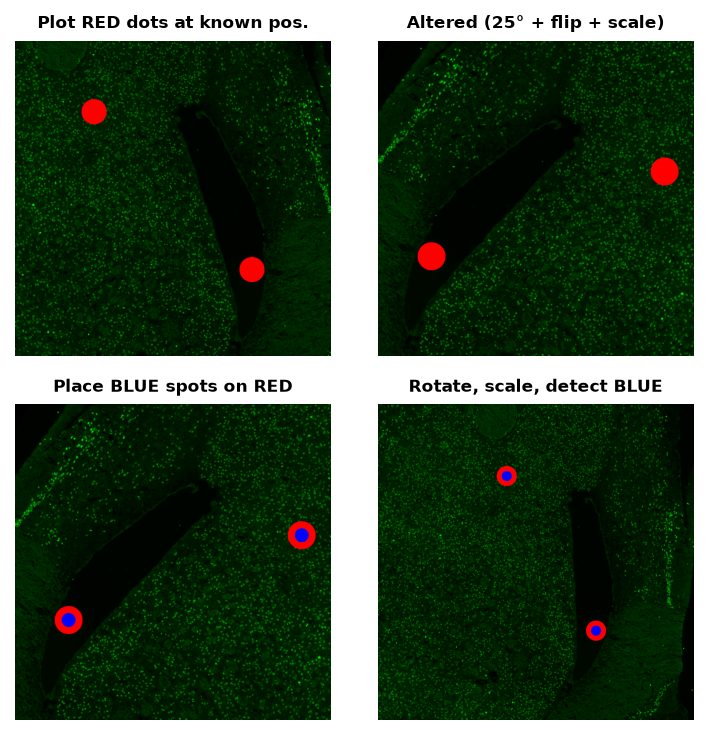

In [18]:
import cv2
import numpy as np

from platpy.demo_utils import detect_circles, match_to_predicted, create_demo_base_layer, BLUE
from platpy.plot_utils import plot_image_grid

# Emulate a UI interaction (e.g., Napari) by detecting features in screen pixel space,
# then use the ViewPort to translate those raw pixels back into absolute microns.
# We will do this twice to simulate a "round trip" of micron -> pixel -> micron, and 
# see how much error is introduced by the transformations and rendering process.

# 1. Make a copy of the NeuN base image that we can draw on, and use it to make a new view. 
#.   We will draw a set of red spots at a known location in micron space so we can track them.
spots_A_um = np.array([[2500, 2100], [3500, 3100]], dtype=float)
neun_rgb   = create_demo_base_layer(sample.images["neun"], spots_A_um)

base_view = sample.viewport(center_um=(3000, 2650), fov_um=(2000, 2000), rotation_deg=0, flip_x=False)
base_view.add_layer(neun_rgb)

panel_1 = base_view.render().image.copy()  # Capture the baseline render


# 2. Change the view and take another render for panel 2.
altered_view = base_view.clone().update_view(center_um=(3100, 2550), fov_um=(1800, 1800), rotation_deg=25.0, flip_x=True)
panel_2 = altered_view.render().image.copy()

# 3. We will look at the screen render (Panel 2) and detect the pixel location of the RED spots baked into the base layer.
# Look at the raw rendered canvas to find the RED spots we baked in

# This detect_circles call is finding the center of mass for the red spots; it's
# scanning the image for red >150, green <100, blue <100, and alpha >200 (fully opaque)
# It's returning pixel coordinates, which we'll turn back to microns.
red_centers = detect_circles(panel_2, [150, 0, 0, 200], [255, 100, 100, 255])

spots_px_2    = altered_view.microns_to_pixels(spots_A_um)
# the following line just sorts the spots to match the order of the initial input so we're comparing the right ones
detected_px_2 = match_to_predicted(red_centers, spots_px_2)

# 4. Now, we will use the ViewPort to find the micron coordinates of the RED spots and draw BLUE spots over them as Panel 3.
detected_um = altered_view.pixels_to_microns(detected_px_2)

#     and now we draw a blue spot at the detected location; smaller so we can stil see the original.
spot_r_blue    = max(1, int(40 / neun_rgb.mpp)) # Half size to create a bullseye
native_px_blue = neun_rgb.microns_to_pixels(detected_um).round().astype(int)  # where to plot them on base image

for px in native_px_blue:
    cv2.circle(neun_rgb.image, (int(px[0]), int(px[1])), radius=spot_r_blue, color=BLUE, thickness=-1)   # type: ignore

panel_3 = altered_view.render().image.copy()  # Render the added blue spots as Panel 3.

# 5. Switch the view again. Then we'll render our final screen image as panel 4.
final_view = altered_view.clone().update_view(center_um=(2900, 2700), fov_um=(2500, 2500), rotation_deg=-15.0, flip_x=False)
panel_4 = final_view.render().image.copy()

# 6. Now we'll find the blue spots on the screen image one last time.  
#    Then we'll calculate the error -- how far off are we from the start?
blue_centers_4  = detect_circles(panel_4, [0, 0, 150, 200], [100, 100, 255, 255])
spots_px_4      = final_view.microns_to_pixels(spots_A_um) # Match against truth
final_px_4      = match_to_predicted(blue_centers_4, spots_px_4)
final_um        = final_view.pixels_to_microns(final_px_4)


# ── PRINT & PLOT ────────────────────────────────────────────────────────────
err_um = np.linalg.norm(spots_A_um - final_um, axis=1)
print("True Render Round-trip: Absolute Truth (RED) -> Detect -> Math -> Render (BLUE) -> Detect -> Error")
for i, label in enumerate(["  Spot 1", "  Spot 2"]):
    m, f = spots_A_um[i], final_um[i]
    print(f"{label}: Start ({m[0]:.1f}, {m[1]:.1f}) µm -> Return ({f[0]:.3f}, {f[1]:.3f}) µm | error = {err_um[i]:.3f} µm")

plot_image_grid([panel_1, panel_2, panel_3, panel_4],
    titles=["Plot RED dots at known pos.",
            "Altered (25° + flip + scale)",
            "Place BLUE spots on RED",
            "Rotate, scale, detect BLUE"],
    width=5, show_axis=False, columns=2, font_size='small');

#### Test: User Interaction
In this test we will generate a view of the above image, and launch a simple GUI interface, Napari.

Draw one or more ROIs in the Napari viewer -- feel free to scroll, zoom, whatever. 

When you're done, DON'T CLOSE NAPARI; instead come back here and run the next cell.  platpy will bring in the ROIs that you just drew and convert them back to micron space.

In [21]:
import numpy as np
import napari


# ======================================
# ── LAUNCH NAPARI FOR POLYGON ROIs ────
# ======================================
print("\n" + "="*78)
print(".                LAUNCHING NAPARI INTERACTIVE MODE...")
print(".   Draw one or more Polygon ROIs, then RUN THE NEXT CELL to harvest them.")
print(".  -----   don't close Napari until after you've run the next cell!   -----")
print("="*78)
# Grab the rendered image from our base ViewPort
napari_img = base_view.render().image

# Launch Napari
viewer = napari.Viewer()
viewer.add_image(napari_img, name="Base View", rgb=True)

# Add a shapes layer specifically for Polygons
poly_layer = viewer.add_shapes(
    name="Poly ROIs",
    shape_type='polygon',
    edge_color='magenta',
    face_color='transparent',
    edge_width=5
)

# AT THIS POINT NAPARI WILL OPEN FOR THE USER TO DRAW A SAMPLE POLYGON ROI (or ROIs).

# AFTER DRAWING ROIS, LEAVE NAPARI OPEN AND RUN THE NEXT CELL TO HARVEST THE POLYGON COORDINATES.  
# NAPARI WILL AUTOMATICALLY CLOSE AS THE POLYGON COORDINATES ARE RETRIEVED.


.                LAUNCHING NAPARI INTERACTIVE MODE...
.   Draw one or more Polygon ROIs, then RUN THE NEXT CELL to harvest them.
.  -----   don't close Napari until after you've run the next cell!   -----


DRAW AN ROI IN NAPARI, then RUN THE NEXT CELL (leave napari open)

Harvested 1 Polygon ROIs in Absolute Micron Space!
ROIs successfully saved to sample.rois['User ROIs']


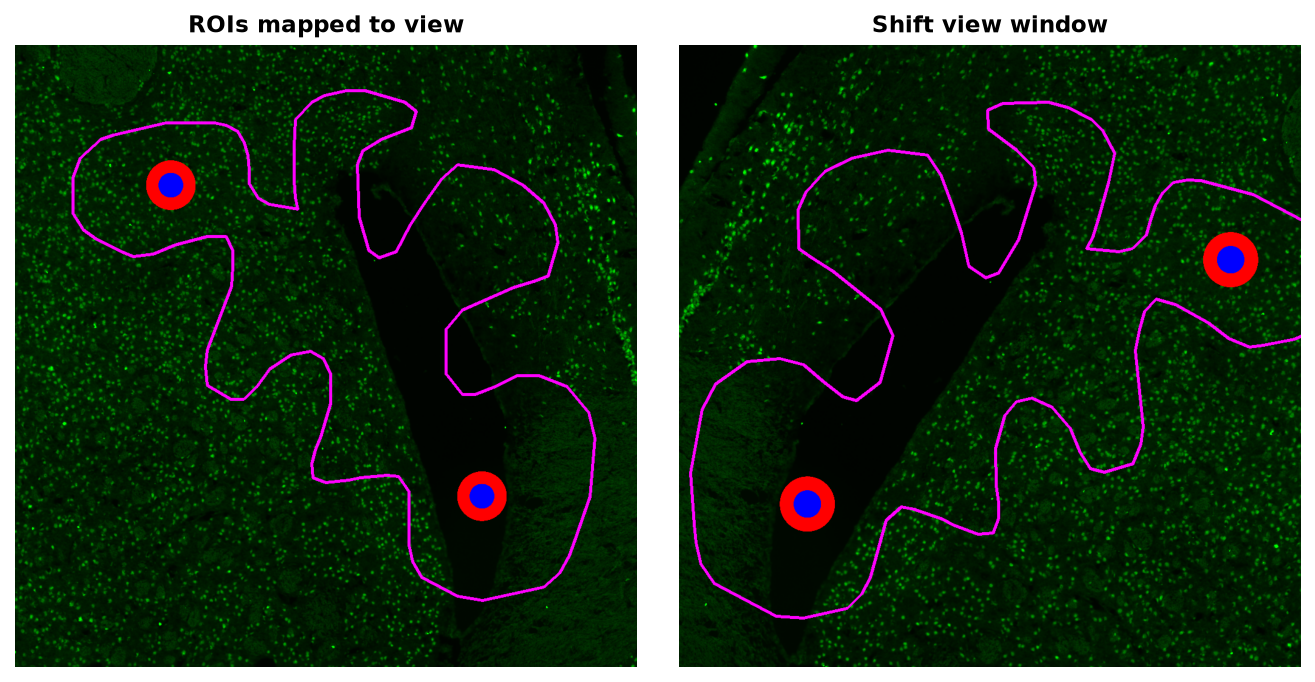

In [22]:

# ==================================
# ── HARVEST POLY ROIS AND CLOSE ───
# ==================================
# 1. Harvest the data from the open viewer
raw_polygons = poly_layer.data

# 2. Safely close the viewer window now that we have the data
viewer.close()

harvested_poly_microns = []
for poly_yx in raw_polygons:
    # Napari coordinates are (Y, X). We swap them to (X, Y) for platpy.
    poly_px = poly_yx[:, [1, 0]]
    
    # MAGIC HAPPENS HERE: Use the ViewPort to instantly map UI pixels to Absolute Microns
    poly_um = base_view.pixels_to_microns(poly_px)
    harvested_poly_microns.append(poly_um)

print(f"Harvested {len(harvested_poly_microns)} Polygon ROIs in Absolute Micron Space!")

if harvested_poly_microns:
    # 3. Create a platpy ROIChannel and store it in the SampleSet
    poly_dict = {f"drawn_roi_{i+1}": poly for i, poly in enumerate(harvested_poly_microns)}
    user_rois = ROIChannel(name="User ROIs", polygons=poly_dict)
    
    # Configure its default display aesthetics natively
    user_rois.set_style(line_color='magenta', line_width=4, fill=False)
    
    sample.add_roi(user_rois)
    print("ROIs successfully saved to sample.rois['User ROIs']")
    # 4, Show where the ROIs land on the view sent to Napari
    roi_view = base_view.clone()
    roi_view.add_layer(user_rois)  # Add the ROIs to the base view
    roi_view_image = roi_view.render().image  # Render the ROIs on the original view for panel 1

    # 5. Shift the view window, and show the ROIs still map as the user drew them!
    roi_view.update_view(center_um=(3100, 2550), fov_um=(1800, 1800), rotation_deg=15.0, flip_x=True)
    shifted_view_image = roi_view.render().image

    plot_image_grid(roi_view_image, shifted_view_image, titles=["ROIs mapped to view", "Shift view window"], columns=2, width=9, show_axis=False);


#### The ViewPort is simple, fast, and accurate

As shown above, the ViewPort is simple to use: 

- **Platpy allows for rotating, cropping, and flipping images easily.** You do not have to worry about scale factors, offsets, or registration issues, because all the information needed is stored with the images and data. 
- **Images and data are handled quickly.** Even when handling large images or datasets, the ViewPort is optimized for efficiency. Platpy uses an affine matrix to track the geometry of each image, allowing us to render complex data quickly using the same highly efficient display methods found in modern video games. 
- **The ViewPort is not just for pretty pictures.**  The method of aligning and rendering images is bidirectional. We can run the math backwards to instantly link any point you click on the screen to its starting location in the real world. 

Next: We're going to use a modified version of the ViewPort to work with your data quickly and efficiently.